# Affine Subspaces and Graph Routing: Baseline Atlas-DeePC Ablation

A paired **500-seed experiment, seeds 211–710**, testing two baseline components separately and together. There is no contextual atlas, rescue, or candidate-goal reselection. The augmented terminal reference and goal chart are constructed once from the initial posture using the original baseline helper, then held fixed.

| Method | Cached chart representation | Online reference |
|---|---|---|
| Affine + graph (baseline) | Centered SVD with chart mean | Original graph waypoints and 7 cm handoff |
| Linear + graph | Uncentered SVD, zero offset | Original graph waypoints and 7 cm handoff |
| Affine + terminal | Centered SVD with chart mean | Fixed terminal configuration at every step |
| Linear + terminal | Uncentered SVD, zero offset | Fixed terminal configuration at every step |

All methods use the same offline data, 48 physical chart assignments, current-chart selection, rank 60, coefficient-bound rule, QP weights, constraints, solver, 320 steps, and success definition. This panel has been used previously; it is a paired ablation, not a new untouched test set.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[variable] = "1"

import sys
import json
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/basis_routing_ablation.py").exists()), None)
assert ROOT is not None
sys.path.insert(0, str(ROOT / "src"))
import routed_deepc_experiment as baseline
import basis_routing_ablation as experiment

SEEDS = list(range(211, 711))
RUN_EXPERIMENTS = True
OVERWRITE = False
DATA_PATH = ROOT / "data/select_iid_offline_hankel.npy"
RESULT_ROOT = ROOT / "experiments/routed_deepc_iid"
ATLAS_PATH = RESULT_ROOT / "clustering_jointconfig48_fresh211_310/behavioral_atlas.npz"
BASELINE_SUMMARY = RESULT_ROOT / "clustering_jointconfig48_baseline_cache/summary.json"
OUTPUT_DIR = RESULT_ROOT / "basis_routing_ablation_500"
original = json.loads(BASELINE_SUMMARY.read_text())
config = baseline.RoutedDeePCConfig(**original["config"])
METHODS = list(experiment.METHODS)
assert config.clusters == 48 and config.svd_rank == 60 and config.steps == 320
assert config.formulation == "svd_current" and config.target_matrix_mode == "current"
print(f"{len(SEEDS)} paired seeds: {SEEDS[0]}–{SEEDS[-1]}; {len(METHODS)} methods")
display(pd.Series(vars(config), name="Shared baseline configuration"))

500 paired seeds: 211–710; 4 methods


clusters                                                  48
cluster_seed                                              11
clustering_input_weight                                  0.0
clustering_method                           minibatch_kmeans
clustering_feature_mode            plant_joint_configuration
clustering_subspace_rank                                   6
clustering_max_iter                                       20
clustering_configuration_weight                          1.0
clustering_velocity_weight                               1.0
clustering_fingertip_weight                              1.0
formulation                                      svd_current
overlap_charts                                             2
svd_rank                                                  60
svd_bound_scale                                          3.0
negative_mass                                            0.2
edge_count_threshold                                       3
target_switch_distance  

## 1. Representation ablation

Let $X_k$ contain the full input-output Hankel columns assigned to current chart $k$, and let $b=[u_{ini};u_f;y_{ini}+\sigma;y_f]$ denote the optimized trajectory.

**Baseline affine representation:**

$$\bar h_k=\operatorname{mean}(X_k),\quad V_k=\operatorname{SVD}_{60}(X_k-\bar h_k),\quad b=\bar h_k+V_kg.$$

**Linear subspace representation:**

$$U_k=\operatorname{SVD}_{60}(X_k),\quad b=U_kg.$$

Both keep 60 orthonormal basis columns. The same empirical coefficient bounds are recalculated in the relevant coordinates: for $a_i=V_k^T(x_i-\bar h_k)$ or $a_i=U_k^Tx_i$, use $\operatorname{mean}(a)\pm3\operatorname{std}(a)$ with the existing numerical standard-deviation floor. The $\lambda_g\|g\|_2^2$ penalty is also retained.

Thus the linear predictor has no explicit affine offset; it still has the baseline coefficient constraints. Its coefficient mean generally is nonzero, and coefficient regularization acts on those uncentered coordinates. This is the direct uncentered-SVD ablation, with no additional regularization retuning.

## 2. Reference ablation

For the terminal-only variants, $r_t=y^*$ for all $t$ and across the prediction horizon. Graph search is skipped entirely. Current-chart localization continues every step, and DeePC receives that current chart's cached behavioral basis. The terminal configuration is identical across all four methods for a given seed.

For graph variants, the unchanged baseline selects medoid waypoints and permanently switches to the fixed terminal reference after entering the 7 cm handoff region.

## 3. Execute the paired panel

All four methods are run sequentially with one numerical-library thread, rotating their order across seeds. The baseline is rerun in this same session for timing comparability. Per-rollout checkpoints allow resume; change `OUTPUT_DIR` or use `OVERWRITE=True` for fresh timing.

Per-step timing separates current-chart localization, routing/reference bookkeeping, behavioral-matrix lookup, the complete DeePC solve call, and other control overhead. Environment stepping and file saving are excluded. Offline chart SVD and one-time goal construction are reported separately. Solver-call timing includes problem construction and canonicalization as in the existing baseline.

In [2]:
if RUN_EXPERIMENTS:
    payload = experiment.run_panel(SEEDS, config, DATA_PATH, ATLAS_PATH, OUTPUT_DIR,
                                   overwrite=OVERWRITE, progress_every=10)
else:
    payload = json.loads((OUTPUT_DIR / "summary.json").read_text())
frame = pd.DataFrame([r for r in payload["results"] if r["seed"] in SEEDS])
assert not frame.duplicated(["method", "seed"]).any()
for method in METHODS:
    assert set(frame.loc[frame.method == method, "seed"]) == set(SEEDS)
assert (frame.groupby("seed").data_goal_index.nunique() == 1).all()
assert (frame.goal_sample_switches == 0).all()
assert (frame.loc[frame.reference_mode == "terminal", "reference_change_steps"] == 0).all()
frame["strict_success"] = frame.success_30 & frame.success_100
frame["amortized_step_ms"] = frame.mean_control_compute_time_ms + frame.goal_setup_time_ms / config.steps
display(pd.Series(payload["manifest"]["offline_times"], name="Shared offline preparation (seconds)"))
print("All methods use the same fixed terminal configuration for each seed.")

10/2000: seed 213, Linear + terminal, strict=True, tail100=3.010 mm


20/2000: seed 215, Linear + terminal, strict=True, tail100=1.128 mm


30/2000: seed 218, Affine + graph (baseline), strict=True, tail100=3.579 mm


40/2000: seed 220, Affine + graph (baseline), strict=True, tail100=1.276 mm


50/2000: seed 223, Linear + graph, strict=True, tail100=1.746 mm


60/2000: seed 225, Linear + graph, strict=True, tail100=1.707 mm


... (192 outputs left out)

1990/2000: seed 708, Affine + terminal, strict=True, tail100=2.286 mm


2000/2000: seed 710, Affine + terminal, strict=False, tail100=321.642 mm

source_metadata_s     0.493991
affine_chart_svd_s    0.134401
linear_chart_svd_s    0.125951
Name: Shared offline preparation (seconds), dtype: float64

All methods use the same fixed terminal configuration for each seed.


## 4. Success and paired comparisons

In [3]:
def wilson(successes, total):
    z = 1.959963984540054
    p = successes / total
    center = (p + z*z/(2*total)) / (1 + z*z/total)
    half = z * np.sqrt(p*(1-p)/total + z*z/(4*total*total)) / (1 + z*z/total)
    return center-half, center+half

records = []
for method in METHODS:
    g = frame[frame.method == method]
    successes = int(g.strict_success.sum())
    lo, hi = wilson(successes, len(g))
    records.append({"method": method, "successes": successes, "rollouts": len(g),
                    "success_pct": 100*successes/len(g), "CI_low_pct": 100*lo, "CI_high_pct": 100*hi,
                    "median_tail100_mm": 1000*g.mean_last_100.median(),
                    "mean_step_ms": g.mean_control_compute_time_ms.mean(),
                    "median_rollout_median_ms": g.median_control_compute_time_ms.median(),
                    "mean_amortized_step_ms": g.amortized_step_ms.mean(),
                    "mean_goal_setup_ms": g.goal_setup_time_ms.mean(),
                    "total_unsolved_steps": int(g.unsolved_steps.sum())})
summary = pd.DataFrame(records).set_index("method").loc[METHODS]
display(summary.round(4))
success = frame.pivot(index="seed", columns="method", values="strict_success").loc[SEEDS]
pairs = [(METHODS[0], method) for method in METHODS[1:]] + [(METHODS[1], METHODS[3]), (METHODS[2], METHODS[3])]
paired = []
for first, second in pairs:
    repaired = success.index[~success[first] & success[second]].tolist()
    regressed = success.index[success[first] & ~success[second]].tolist()
    a, b = len(repaired), len(regressed)
    n = a+b
    p = 1.0 if n == 0 else min(1.0, 2*sum(math.comb(n,j) for j in range(min(a,b)+1))/2**n)
    paired.append({"first": first, "second": second, "repaired": a, "regressed": b, "net": a-b,
                   "McNemar_p_unadjusted": p, "repaired_seeds": repaired, "regressed_seeds": regressed})
display(pd.DataFrame(paired).style.format({"McNemar_p_unadjusted": "{:.3g}"}))
summary.to_csv(OUTPUT_DIR / "method_summary.csv")
(OUTPUT_DIR / "paired_comparisons.json").write_text(json.dumps(paired, indent=2))

,successes,rollouts,success_pct,CI_low_pct,CI_high_pct,median_tail100_mm,mean_step_ms,median_rollout_median_ms,mean_amortized_step_ms,mean_goal_setup_ms,total_unsolved_steps
method,,,,,,,,,,,
Affine + graph (baseline),443,500,88.6,85.5151,91.0963,2.1614,34.2320,32.3882,34.2515,6.2637,0
Linear + graph,446,500,89.2,86.1745,91.6277,2.0372,33.9301,32.1009,33.9491,6.0833,0
Affine + terminal,400,500,80.0,76.2711,83.2715,2.3676,35.0649,32.5884,35.0848,6.3707,0
Linear + terminal,402,500,80.4,76.6943,83.6422,2.2745,34.9035,32.1851,34.9225,6.0860,0


,first,second,repaired,regressed,net,McNemar_p_unadjusted,repaired_seeds,regressed_seeds
0,Affine + graph (baseline),Linear + graph,12,9,3,0.664,"[254, 266, 283, 325, 343, 362, 445, 449, 526, 542, 605, 645]","[290, 296, 320, 326, 517, 548, 558, 611, 691]"
1,Affine + graph (baseline),Affine + terminal,0,43,-43,2.27e-13,[],"[236, 237, 241, 256, 262, 269, 284, 287, 294, 296, 306, 318, 336, 339, 377, 379, 421, 427, 433, 436, 450, 474, 479, 482, 495, 498, 527, 531, 557, 562, 565, 577, 589, 609, 623, 632, 660, 661, 678, 690, 699, 707, 710]"
2,Affine + graph (baseline),Linear + terminal,11,52,-41,1.67e-07,"[254, 266, 283, 343, 362, 419, 445, 449, 526, 542, 605]","[236, 237, 241, 256, 262, 269, 284, 290, 293, 294, 296, 306, 318, 320, 336, 377, 379, 421, 427, 433, 436, 450, 451, 474, 479, 482, 495, 498, 527, 531, 548, 557, 558, 560, 562, 565, 577, 579, 589, 609, 611, 623, 632, 660, 661, 678, 690, 691, 696, 699, 707, 710]"
3,Linear + graph,Linear + terminal,3,47,-44,3.71e-11,"[326, 419, 517]","[236, 237, 241, 256, 262, 269, 284, 293, 294, 306, 318, 325, 336, 377, 379, 421, 427, 433, 436, 450, 451, 474, 479, 482, 495, 498, 527, 531, 557, 560, 562, 565, 577, 579, 589, 609, 623, 632, 645, 660, 661, 678, 690, 696, 699, 707, 710]"
4,Affine + terminal,Linear + terminal,13,11,2,0.839,"[254, 266, 283, 287, 339, 343, 362, 419, 445, 449, 526, 542, 605]","[290, 293, 320, 451, 548, 558, 560, 579, 611, 691, 696]"


3446

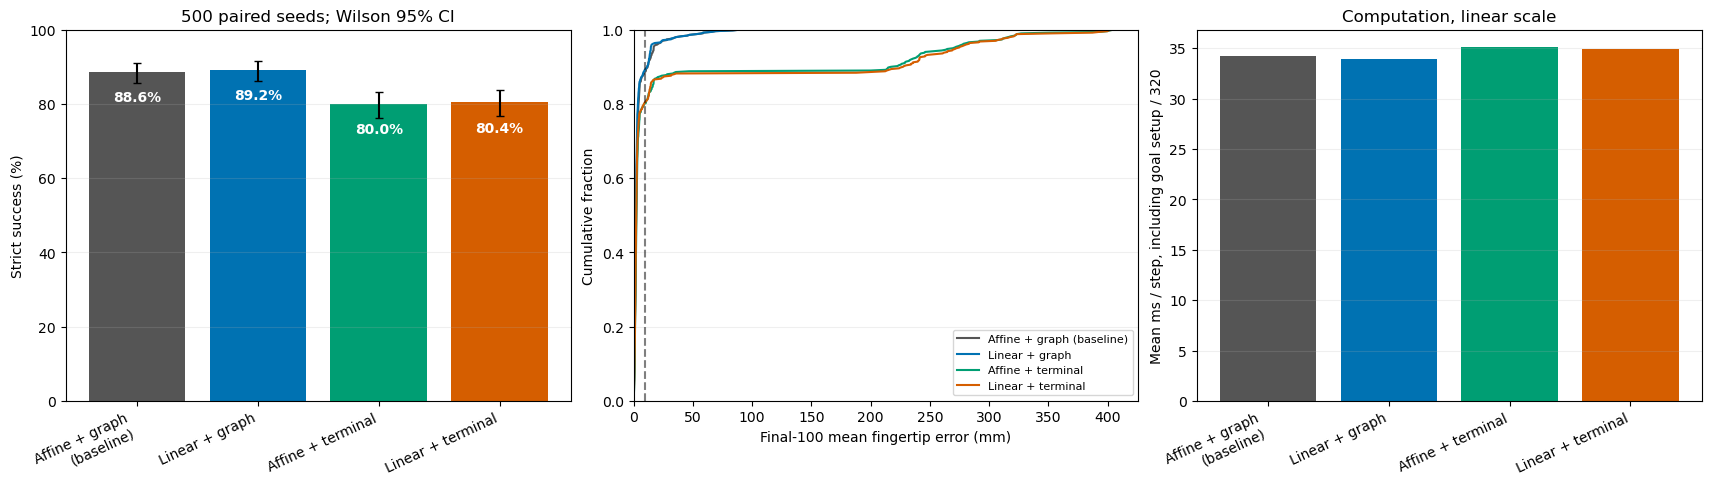

In [4]:
colors = ["#555555", "#0072B2", "#009E73", "#D55E00"]
labels = ["Affine + graph\n(baseline)", "Linear + graph", "Affine + terminal", "Linear + terminal"]
x = np.arange(len(METHODS))
fig, axes = plt.subplots(1,3, figsize=(17,4.8), constrained_layout=True)
axes[0].bar(x, summary.success_pct, color=colors)
axes[0].errorbar(x, summary.success_pct,
                yerr=np.maximum(0,np.vstack([summary.success_pct-summary.CI_low_pct,summary.CI_high_pct-summary.success_pct])),
                fmt="none", color="black", capsize=3)
axes[0].set(ylabel="Strict success (%)", ylim=(0,100), title="500 paired seeds; Wilson 95% CI")
for i,value in enumerate(summary.success_pct):
    axes[0].text(i,max(2,value-8),f"{value:.1f}%",ha="center",color="white" if value>10 else "black",weight="bold")
for i,method in enumerate(METHODS):
    error = np.sort(1000*frame.loc[frame.method == method,"mean_last_100"])
    axes[1].plot(error, np.arange(1,len(error)+1)/len(error), color=colors[i], label=method)
axes[1].axvline(10,color="black",linestyle="--",alpha=.5)
axes[1].set(xlabel="Final-100 mean fingertip error (mm)", ylabel="Cumulative fraction", xlim=(0,None),ylim=(0,1))
axes[1].legend(fontsize=8)
axes[2].bar(x, summary.mean_amortized_step_ms, color=colors)
axes[2].set(ylabel="Mean ms / step, including goal setup / 320",ylim=(0,None),title="Computation, linear scale")
for ax in (axes[0],axes[2]):
    ax.set_xticks(x,labels,rotation=25,ha="right")
for ax in axes:
    ax.grid(axis="y",alpha=.2)
fig.savefig(OUTPUT_DIR / "success_and_runtime.png",dpi=170)
plt.show()

## 5. Module timing

The stacked components are means of per-rollout means, so they sum to total mean control computation. The no-routing variants retain minimal reference/distance bookkeeping; their routing-time field does not imply that graph search was called.

,Current-chart localization,Routing / reference bookkeeping,Matrix lookup,DeePC solve call,Other overhead
method,,,,,
Affine + graph (baseline),0.06563,0.02009,0.00075,34.10435,0.04114
Linear + graph,0.06555,0.01999,0.00075,33.80257,0.04122
Affine + terminal,0.06646,0.00434,0.00075,34.95099,0.04231
Linear + terminal,0.06675,0.00434,0.00075,34.78914,0.04253


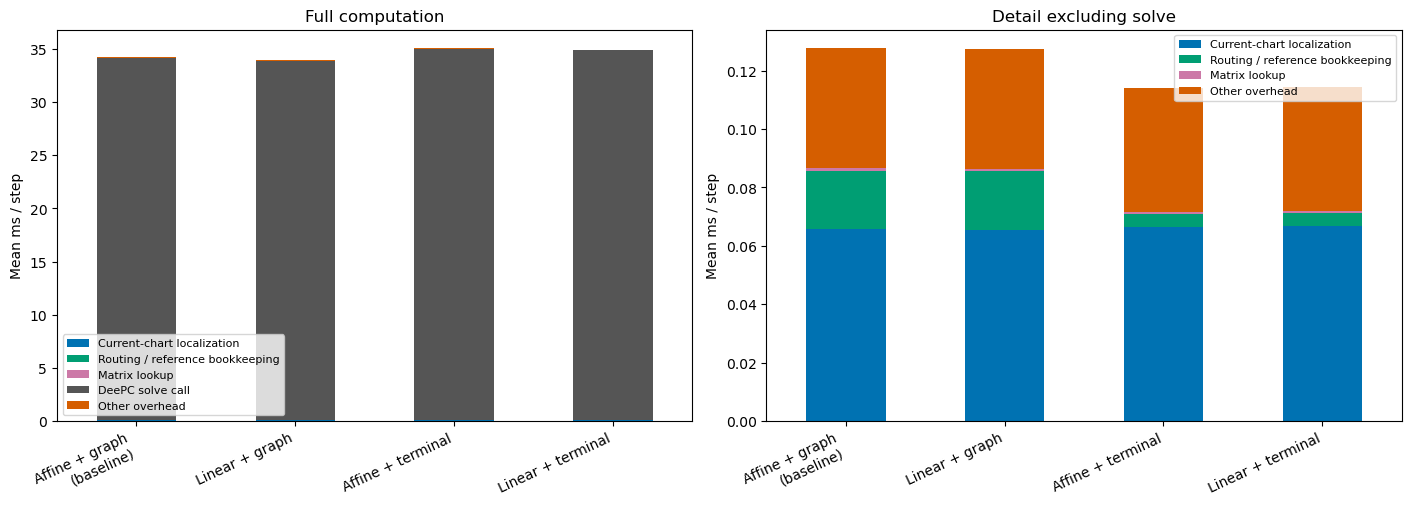

,p95_control_compute_time_ms,p95_solve_time_ms,goal_setup_time_ms
method,,,
Affine + graph (baseline),38.5448,38.3774,6.2637
Linear + graph,38.0842,37.9075,6.0833
Affine + terminal,39.8835,39.7575,6.3707
Linear + terminal,39.7551,39.6199,6.0860


In [5]:
components = {"mean_localization_time_ms": "Current-chart localization",
              "mean_routing_time_ms": "Routing / reference bookkeeping",
              "mean_matrix_preparation_time_ms": "Matrix lookup",
              "mean_solve_time_ms": "DeePC solve call",
              "mean_other_time_ms": "Other overhead"}
times = frame.groupby("method")[list(components)].mean().reindex(METHODS)
assert np.allclose(times.sum(axis=1),summary.mean_step_ms)
display(times.rename(columns=components).round(5))
fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
times.rename(columns=components).plot.bar(stacked=True,ax=axes[0],color=["#0072B2","#009E73","#CC79A7","#555555","#D55E00"])
times.drop(columns="mean_solve_time_ms").rename(columns=components).plot.bar(stacked=True,ax=axes[1],color=["#0072B2","#009E73","#CC79A7","#D55E00"])
for ax,title in zip(axes,["Full computation","Detail excluding solve"]):
    ax.set(xlabel="",ylabel="Mean ms / step",ylim=(0,None),title=title)
    ax.set_xticklabels(labels,rotation=25,ha="right")
    ax.legend(fontsize=8)
fig.savefig(OUTPUT_DIR / "module_runtime.png",dpi=170)
plt.show()
display(frame.groupby("method")[["p95_control_compute_time_ms","p95_solve_time_ms","goal_setup_time_ms"]].mean().reindex(METHODS).round(4))

## 6. Seed-level behavior and integrity checks

,method,strict_success,mean_last_30,mean_last_100,unsolved_steps
264,Affine + terminal,False,0.015379,0.015379,0
265,Linear + terminal,False,0.025668,0.025668,0
266,Affine + graph (baseline),False,0.058574,0.058574,0
267,Linear + graph,False,0.057230,0.057230,0


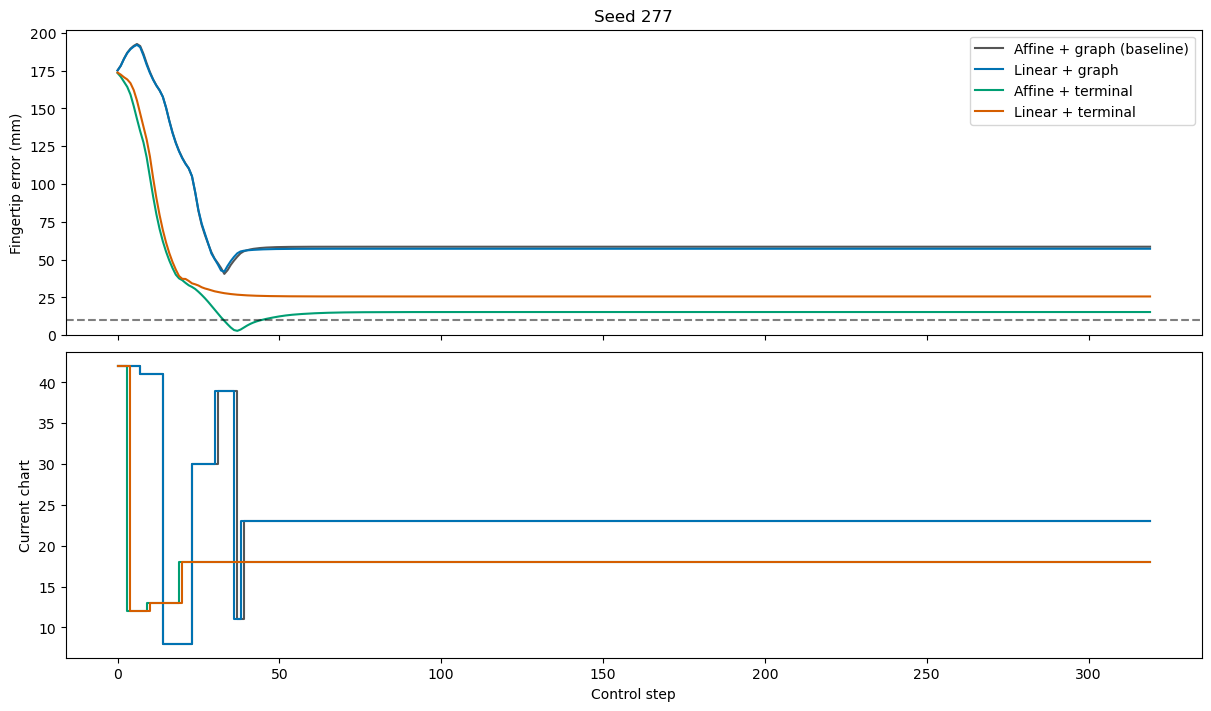

original baseline labels matched       5.000000e+02
baseline seeds compared                5.000000e+02
max baseline tail100 difference (m)    1.168302e-13
dtype: float64

In [6]:
SEED_TO_INSPECT = 277
if SEED_TO_INSPECT in SEEDS:
    display(frame.loc[frame.seed == SEED_TO_INSPECT,["method","strict_success","mean_last_30","mean_last_100","unsolved_steps"]])
    fig,axes = plt.subplots(2,1,figsize=(12,7),sharex=True,constrained_layout=True)
    for i,(method,(geometry,reference_mode)) in enumerate(experiment.METHODS.items()):
        with np.load(OUTPUT_DIR / f"{geometry}_{reference_mode}" / f"seed{SEED_TO_INSPECT}.npz") as tr:
            axes[0].plot(1000*tr["distance"],label=method,color=colors[i])
            axes[1].step(np.arange(config.steps),tr["chart"],where="post",label=method,color=colors[i])
    axes[0].axhline(10,color="black",linestyle="--",alpha=.5)
    axes[0].set(ylabel="Fingertip error (mm)",ylim=(0,None),title=f"Seed {SEED_TO_INSPECT}")
    axes[0].legend()
    axes[1].set(xlabel="Control step",ylabel="Current chart")
    plt.show()

assert not frame.fitted_dynamics_model.any()
assert not frame.online_nearest_trajectory_retrieval.any()
assert (frame.data_goal_source_target_distance >= config.goal_source_target_min_distance).all()
original_by_seed = {r["seed"]:r for r in original["results"]}
checks = []
for row in frame[frame.method == METHODS[0]].to_dict("records"):
    if row["seed"] in original_by_seed:
        old = original_by_seed[row["seed"]]
        checks.append({"seed":row["seed"],"success_matches":experiment.strict_success(row)==experiment.strict_success(old),
                       "tail100_difference_m":abs(row["mean_last_100"]-old["mean_last_100"])})
if checks:
    check_frame = pd.DataFrame(checks)
    display(pd.Series({"original baseline labels matched":int(check_frame.success_matches.sum()),
                       "baseline seeds compared":len(check_frame),
                       "max baseline tail100 difference (m)":check_frame.tail100_difference_m.max()}))